In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

## 0. Load Data

In [2]:
data = pd.read_csv("../data/data.csv")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68206 entries, 0 to 68205
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Fecha-I    68206 non-null  object
 1   Vlo-I      68206 non-null  object
 2   Ori-I      68206 non-null  object
 3   Des-I      68206 non-null  object
 4   Emp-I      68206 non-null  object
 5   Fecha-O    68206 non-null  object
 6   Vlo-O      68205 non-null  object
 7   Ori-O      68206 non-null  object
 8   Des-O      68206 non-null  object
 9   Emp-O      68206 non-null  object
 10  DIA        68206 non-null  int64 
 11  MES        68206 non-null  int64 
 12  AÑO        68206 non-null  int64 
 13  DIANOM     68206 non-null  object
 14  TIPOVUELO  68206 non-null  object
 15  OPERA      68206 non-null  object
 16  SIGLAORI   68206 non-null  object
 17  SIGLADES   68206 non-null  object
dtypes: int64(3), object(15)
memory usage: 9.4+ MB


## 1. Data Analysis: First Sight

### How is the date distribuited?

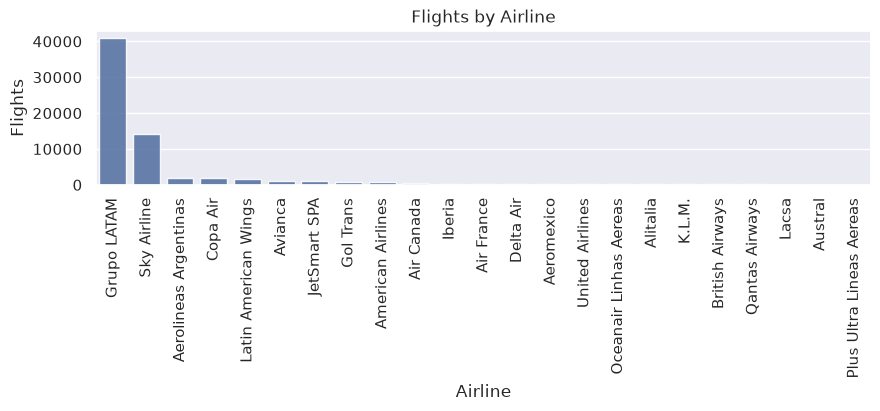

In [3]:
flights_by_airline = data["OPERA"].value_counts()
plt.figure(figsize=(10, 2))
# sns.set(style="darkgrid") ## Deprecated
sns.set_theme(style="darkgrid")
sns.barplot(x=flights_by_airline.index, y=flights_by_airline.values, alpha=0.9)
plt.title("Flights by Airline")
plt.ylabel("Flights", fontsize=12)
plt.xlabel("Airline", fontsize=12)
plt.xticks(rotation=90)
plt.show()

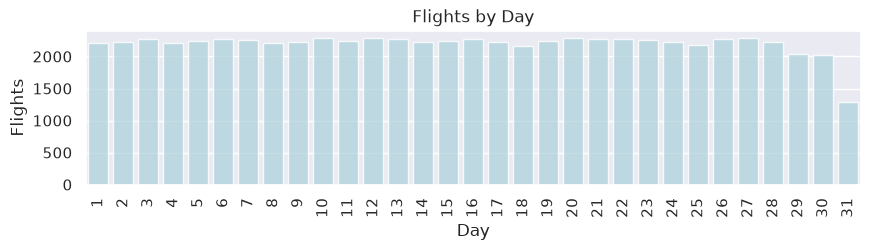

In [4]:
flights_by_day = data["DIA"].value_counts()
plt.figure(figsize=(10, 2))
sns.set_theme(style="darkgrid")
# sns.set(style = "darkgrid")
sns.barplot(
    x=flights_by_day.index, y=flights_by_day.values, color="lightblue", alpha=0.8
)
plt.title("Flights by Day")
plt.ylabel("Flights", fontsize=12)
plt.xlabel("Day", fontsize=12)
plt.xticks(rotation=90)
plt.show()

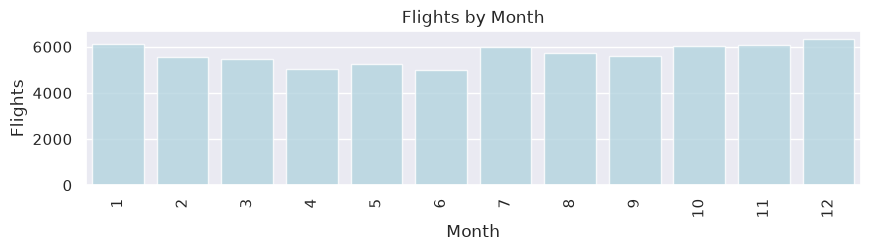

In [5]:
flights_by_month = data["MES"].value_counts()
plt.figure(figsize=(10, 2))
sns.set_theme(style="darkgrid")
# sns.set(style = "darkgrid")
sns.barplot(
    x=flights_by_month.index, y=flights_by_month.values, color="lightblue", alpha=0.8
)
plt.title("Flights by Month")
plt.ylabel("Flights", fontsize=12)
plt.xlabel("Month", fontsize=12)
plt.xticks(rotation=90)
plt.show()

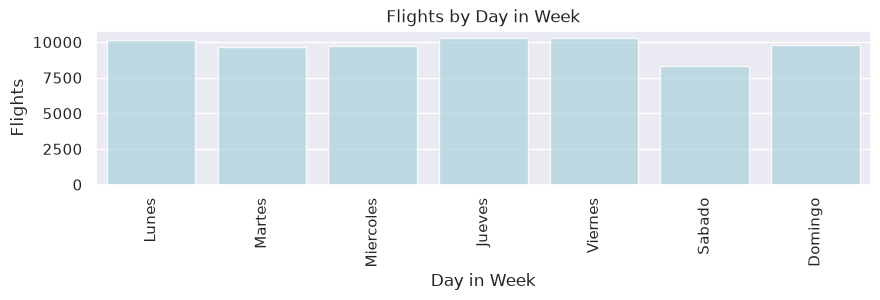

In [6]:
flights_by_day_in_week = data["DIANOM"].value_counts()
days = [
    flights_by_day_in_week.index[2],
    flights_by_day_in_week.index[5],
    flights_by_day_in_week.index[4],
    flights_by_day_in_week.index[1],
    flights_by_day_in_week.index[0],
    flights_by_day_in_week.index[6],
    flights_by_day_in_week.index[3],
]
values_by_day = [
    flights_by_day_in_week.values[2],
    flights_by_day_in_week.values[5],
    flights_by_day_in_week.values[4],
    flights_by_day_in_week.values[1],
    flights_by_day_in_week.values[0],
    flights_by_day_in_week.values[6],
    flights_by_day_in_week.values[3],
]
plt.figure(figsize=(10, 2))
sns.set(style="darkgrid")
sns.barplot(x=days, y=values_by_day, color="lightblue", alpha=0.8)
plt.title("Flights by Day in Week")
plt.ylabel("Flights", fontsize=12)
plt.xlabel("Day in Week", fontsize=12)
plt.xticks(rotation=90)
plt.show()

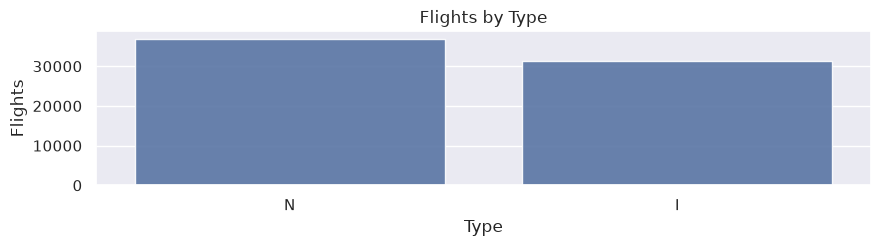

In [7]:
flights_by_type = data["TIPOVUELO"].value_counts()
sns.set(style="darkgrid")
plt.figure(figsize=(10, 2))
sns.barplot(x=flights_by_type.index, y=flights_by_type.values, alpha=0.9)
plt.title("Flights by Type")
plt.ylabel("Flights", fontsize=12)
plt.xlabel("Type", fontsize=12)
plt.show()

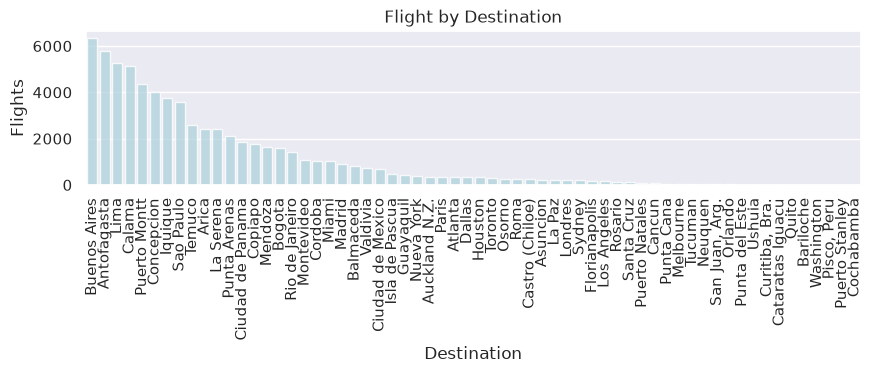

In [8]:
flight_by_destination = data["SIGLADES"].value_counts()
plt.figure(figsize=(10, 2))
sns.set(style="darkgrid")
sns.barplot(
    x=flight_by_destination.index,
    y=flight_by_destination.values,
    color="lightblue",
    alpha=0.8,
)
plt.title("Flight by Destination")
plt.ylabel("Flights", fontsize=12)
plt.xlabel("Destination", fontsize=12)
plt.xticks(rotation=90)

plt.show()

## 2. Features Generation

### 2.a. Period of Day

In [9]:
from datetime import datetime


def get_period_day(date):
    date_time = datetime.strptime(date, "%Y-%m-%d %H:%M:%S").time()
    morning_min = datetime.strptime("05:00", "%H:%M").time()
    morning_max = datetime.strptime("11:59", "%H:%M").time()
    afternoon_min = datetime.strptime("12:00", "%H:%M").time()
    afternoon_max = datetime.strptime("18:59", "%H:%M").time()
    evening_min = datetime.strptime("19:00", "%H:%M").time()
    evening_max = datetime.strptime("23:59", "%H:%M").time()
    night_min = datetime.strptime("00:00", "%H:%M").time()
    night_max = datetime.strptime("4:59", "%H:%M").time()

    if date_time >= morning_min and date_time <= morning_max:
        return "mañana"
    elif date_time >= afternoon_min and date_time <= afternoon_max:
        return "tarde"
    elif (date_time >= evening_min and date_time <= evening_max) or (
        date_time >= night_min and date_time <= night_max
    ):
        return "noche"

In [10]:
data["period_day"] = data["Fecha-I"].apply(get_period_day)

### 2.b. High Season

In [11]:
from datetime import datetime


def is_high_season(fecha):
    fecha_año = int(fecha.split("-")[0])
    fecha = datetime.strptime(fecha, "%Y-%m-%d %H:%M:%S")
    range1_min = datetime.strptime("15-Dec", "%d-%b").replace(year=fecha_año)
    range1_max = datetime.strptime("31-Dec", "%d-%b").replace(year=fecha_año)
    range2_min = datetime.strptime("1-Jan", "%d-%b").replace(year=fecha_año)
    range2_max = datetime.strptime("3-Mar", "%d-%b").replace(year=fecha_año)
    range3_min = datetime.strptime("15-Jul", "%d-%b").replace(year=fecha_año)
    range3_max = datetime.strptime("31-Jul", "%d-%b").replace(year=fecha_año)
    range4_min = datetime.strptime("11-Sep", "%d-%b").replace(year=fecha_año)
    range4_max = datetime.strptime("30-Sep", "%d-%b").replace(year=fecha_año)

    if (
        (fecha >= range1_min and fecha <= range1_max)
        or (fecha >= range2_min and fecha <= range2_max)
        or (fecha >= range3_min and fecha <= range3_max)
        or (fecha >= range4_min and fecha <= range4_max)
    ):
        return 1
    else:
        return 0

In [12]:
data["high_season"] = data["Fecha-I"].apply(is_high_season)

### 2.c. Difference in Minutes

In [13]:
def get_min_diff(data):
    fecha_o = datetime.strptime(data["Fecha-O"], "%Y-%m-%d %H:%M:%S")
    fecha_i = datetime.strptime(data["Fecha-I"], "%Y-%m-%d %H:%M:%S")
    min_diff = ((fecha_o - fecha_i).total_seconds()) / 60
    return min_diff

In [14]:
data["min_diff"] = data.apply(get_min_diff, axis=1)

### 2.d. Delay

In [15]:
threshold_in_minutes = 15
data["delay"] = np.where(data["min_diff"] > threshold_in_minutes, 1, 0)

In [16]:
data.columns

Index(['Fecha-I', 'Vlo-I', 'Ori-I', 'Des-I', 'Emp-I', 'Fecha-O', 'Vlo-O',
       'Ori-O', 'Des-O', 'Emp-O', 'DIA', 'MES', 'AÑO', 'DIANOM', 'TIPOVUELO',
       'OPERA', 'SIGLAORI', 'SIGLADES', 'period_day', 'high_season',
       'min_diff', 'delay'],
      dtype='object')

## 3. Data Analysis: Second Sight

### How is the delay rate across columns?

In [17]:
def get_rate_from_column(data, column):
    delays = {}
    for _, row in data.iterrows():
        if row["delay"] == 1:
            if row[column] not in delays:
                delays[row[column]] = 1
            else:
                delays[row[column]] += 1
    total = data[column].value_counts().to_dict()

    rates = {}
    for name, total in total.items():
        if name in delays:
            rates[name] = round(delays[name] / total, 2)
        else:
            rates[name] = 0

    return pd.DataFrame.from_dict(data=rates, orient="index", columns=["Tasa (%)"])

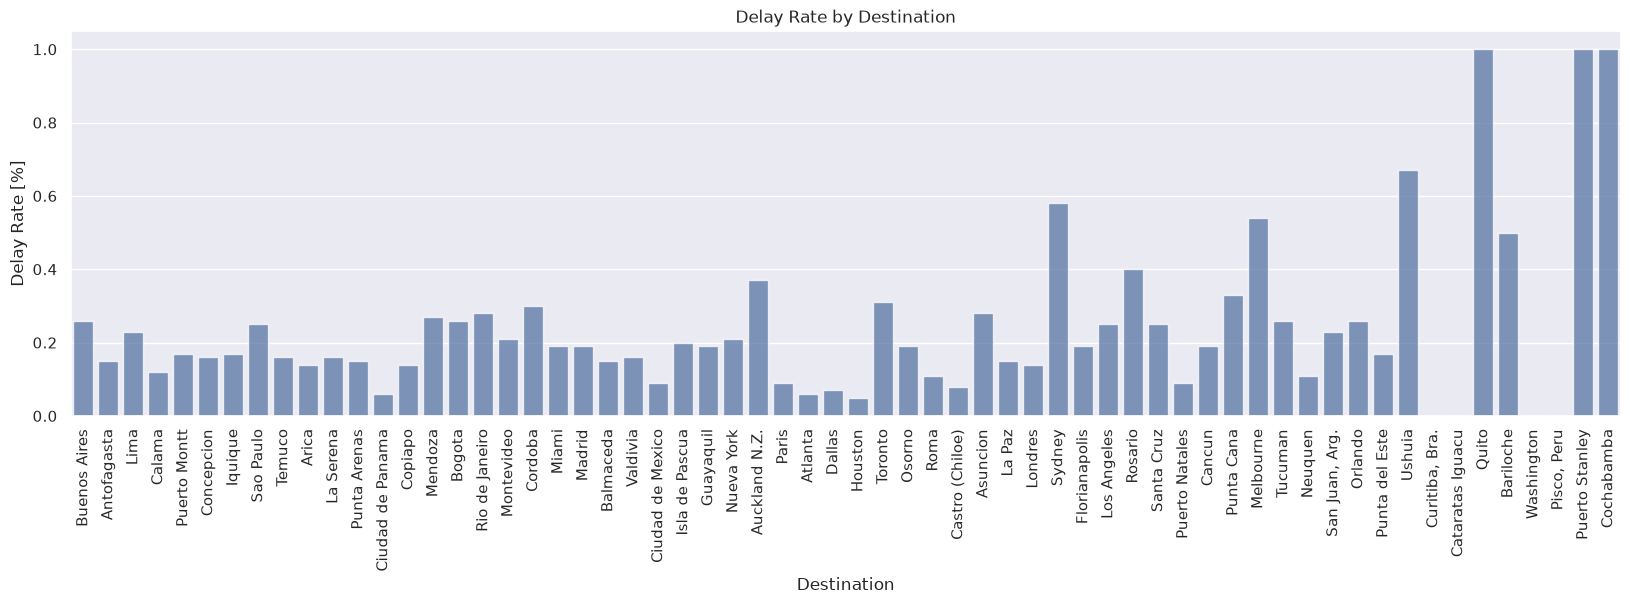

In [18]:
destination_rate = get_rate_from_column(data, "SIGLADES")
destination_rate_values = data["SIGLADES"].value_counts().index
plt.figure(figsize=(20, 5))
sns.set(style="darkgrid")
sns.barplot(x=destination_rate_values, y=destination_rate["Tasa (%)"], alpha=0.75)
plt.title("Delay Rate by Destination")
plt.ylabel("Delay Rate [%]", fontsize=12)
plt.xlabel("Destination", fontsize=12)
plt.xticks(rotation=90)
plt.show()

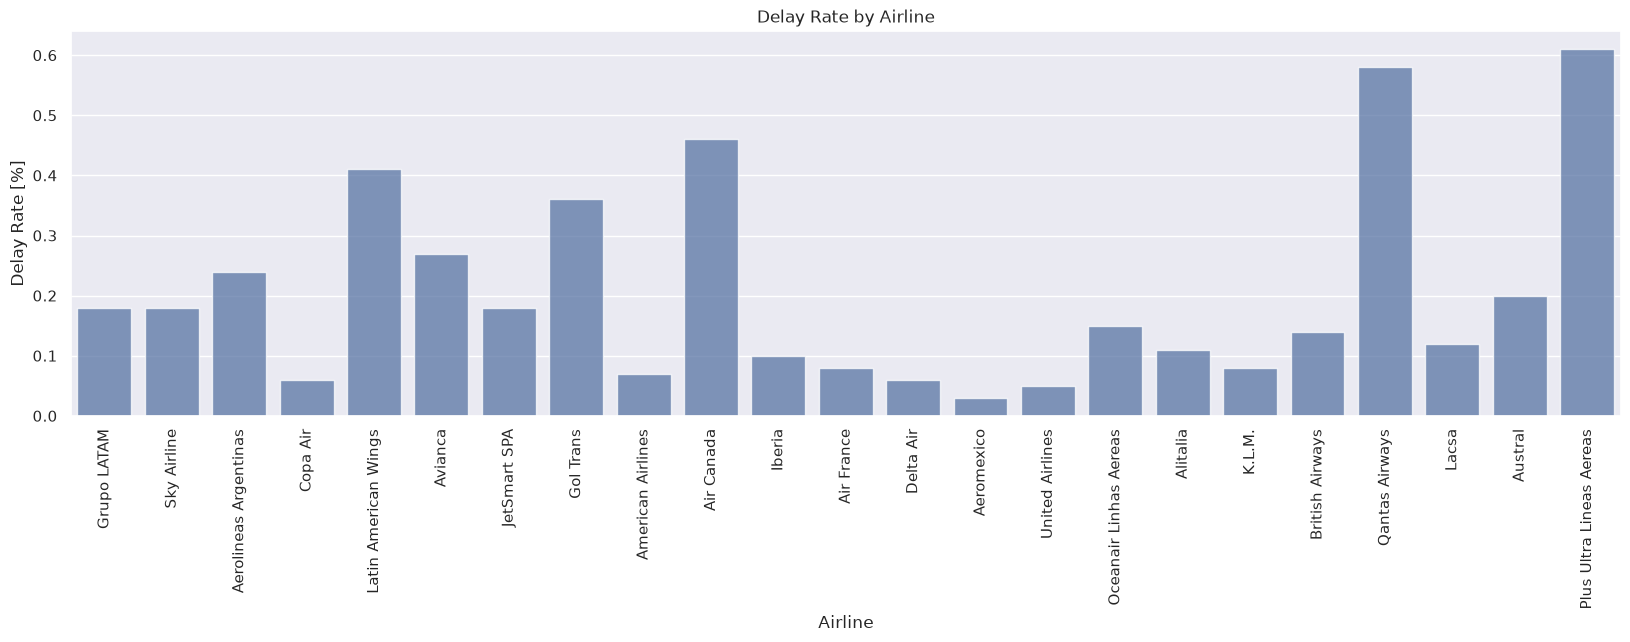

In [19]:
airlines_rate = get_rate_from_column(data, "OPERA")
airlines_rate_values = data["OPERA"].value_counts().index
plt.figure(figsize=(20, 5))
sns.set(style="darkgrid")
sns.barplot(x=airlines_rate_values, y=airlines_rate["Tasa (%)"], alpha=0.75)
plt.title("Delay Rate by Airline")
plt.ylabel("Delay Rate [%]", fontsize=12)
plt.xlabel("Airline", fontsize=12)
plt.xticks(rotation=90)
plt.show()

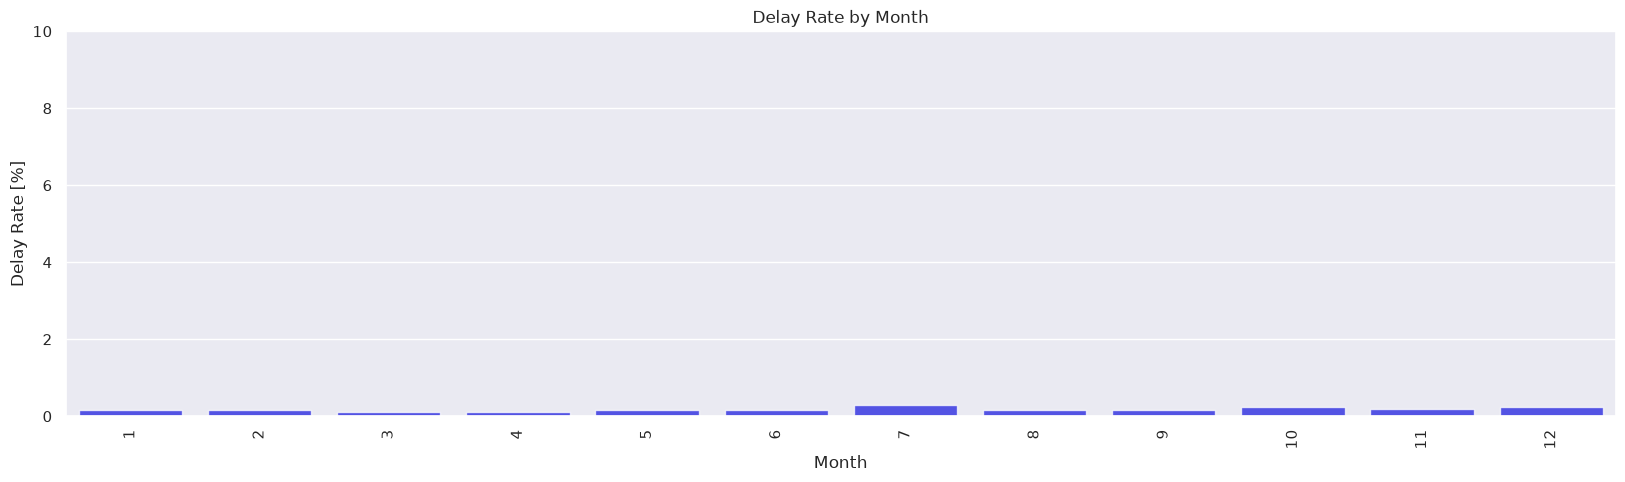

In [20]:
month_rate = get_rate_from_column(data, "MES")
month_rate_value = data["MES"].value_counts().index
plt.figure(figsize=(20, 5))
sns.set(style="darkgrid")
sns.barplot(x=month_rate_value, y=month_rate["Tasa (%)"], color="blue", alpha=0.75)
plt.title("Delay Rate by Month")
plt.ylabel("Delay Rate [%]", fontsize=12)
plt.xlabel("Month", fontsize=12)
plt.xticks(rotation=90)
plt.ylim(0, 10)
plt.show()

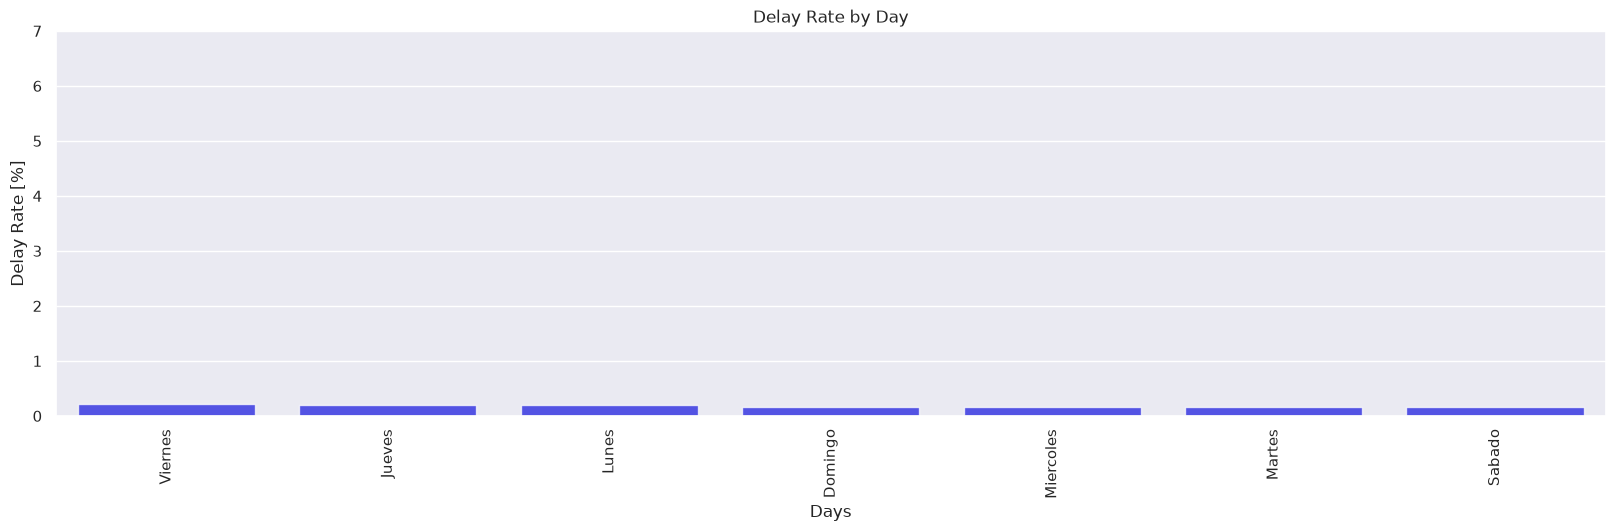

In [21]:
days_rate = get_rate_from_column(data, "DIANOM")
days_rate_value = data["DIANOM"].value_counts().index

sns.set(style="darkgrid")
plt.figure(figsize=(20, 5))
sns.barplot(x=days_rate_value, y=days_rate["Tasa (%)"], color="blue", alpha=0.75)
plt.title("Delay Rate by Day")
plt.ylabel("Delay Rate [%]", fontsize=12)
plt.xlabel("Days", fontsize=12)
plt.xticks(rotation=90)
plt.ylim(0, 7)
plt.show()

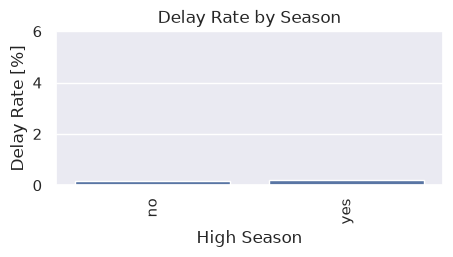

In [22]:
high_season_rate = get_rate_from_column(data, "high_season")
high_season_rate_values = data["high_season"].value_counts().index

plt.figure(figsize=(5, 2))
sns.set(style="darkgrid")
sns.barplot(x=["no", "yes"], y=high_season_rate["Tasa (%)"])
plt.title("Delay Rate by Season")
plt.ylabel("Delay Rate [%]", fontsize=12)
plt.xlabel("High Season", fontsize=12)
plt.xticks(rotation=90)
plt.ylim(0, 6)
plt.show()

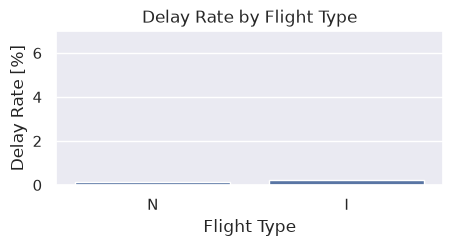

In [23]:
flight_type_rate = get_rate_from_column(data, "TIPOVUELO")
flight_type_rate_values = data["TIPOVUELO"].value_counts().index
plt.figure(figsize=(5, 2))
sns.set(style="darkgrid")
sns.barplot(x=flight_type_rate_values, y=flight_type_rate["Tasa (%)"])
plt.title("Delay Rate by Flight Type")
plt.ylabel("Delay Rate [%]", fontsize=12)
plt.xlabel("Flight Type", fontsize=12)
plt.ylim(0, 7)
plt.show()

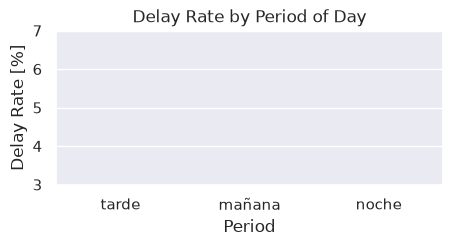

In [24]:
period_day_rate = get_rate_from_column(data, "period_day")
period_day_rate_values = data["period_day"].value_counts().index
plt.figure(figsize=(5, 2))
sns.set(style="darkgrid")
sns.barplot(x=period_day_rate_values, y=period_day_rate["Tasa (%)"])
plt.title("Delay Rate by Period of Day")
plt.ylabel("Delay Rate [%]", fontsize=12)
plt.xlabel("Period", fontsize=12)
plt.ylim(3, 7)
plt.show()

## 4. Training

### 4.a. Data Split (Training and Validation)

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix, classification_report

In [26]:
training_data = shuffle(
    data[["OPERA", "MES", "TIPOVUELO", "SIGLADES", "DIANOM", "delay"]], random_state=111
)

In [27]:
features = pd.concat(
    [
        pd.get_dummies(data["OPERA"], prefix="OPERA"),
        pd.get_dummies(data["TIPOVUELO"], prefix="TIPOVUELO"),
        pd.get_dummies(data["MES"], prefix="MES"),
    ],
    axis=1,
)
target = data["delay"]

In [28]:
x_train, x_test, y_train, y_test = train_test_split(
    features, target, test_size=0.33, random_state=42
)

In [29]:
print(f"train shape: {x_train.shape} | test shape: {x_test.shape}")

train shape: (45698, 37) | test shape: (22508, 37)


In [30]:
y_train.value_counts("%") * 100

delay
0    81.618452
1    18.381548
Name: proportion, dtype: float64

In [31]:
y_test.value_counts("%") * 100

delay
0    81.277768
1    18.722232
Name: proportion, dtype: float64

### 4.b. Model Selection

#### 4.b.i. XGBoost

In [32]:
import xgboost as xgb
from xgboost import plot_importance

In [33]:
xgb_model = xgb.XGBClassifier(random_state=1, learning_rate=0.01)
xgb_model.fit(x_train, y_train)

,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None
,feature_types,None


In [ ]:
xgboost_y_preds = xgb_model.predict(x_test)

In [35]:
confusion_matrix(y_test, xgboost_y_preds)

array([[18294,     0],
       [ 4214,     0]])

In [36]:
print(classification_report(y_test, xgboost_y_preds))

              precision    recall  f1-score   support

           0       0.81      1.00      0.90     18294
           1       0.00      0.00      0.00      4214

    accuracy                           0.81     22508
   macro avg       0.41      0.50      0.45     22508
weighted avg       0.66      0.81      0.73     22508



#### 4.b.ii. Logistic Regression

In [37]:
from sklearn.linear_model import LogisticRegression

In [38]:
reg_model = LogisticRegression()
reg_model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [39]:
reg_y_preds = reg_model.predict(x_test)

In [40]:
confusion_matrix(y_test, reg_y_preds)

array([[18193,   101],
       [ 4086,   128]])

In [41]:
print(classification_report(y_test, reg_y_preds))

              precision    recall  f1-score   support

           0       0.82      0.99      0.90     18294
           1       0.56      0.03      0.06      4214

    accuracy                           0.81     22508
   macro avg       0.69      0.51      0.48     22508
weighted avg       0.77      0.81      0.74     22508



## 5. Data Analysis: Third Sight

### Feature Importance

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

<Figure size 1000x500 with 0 Axes>

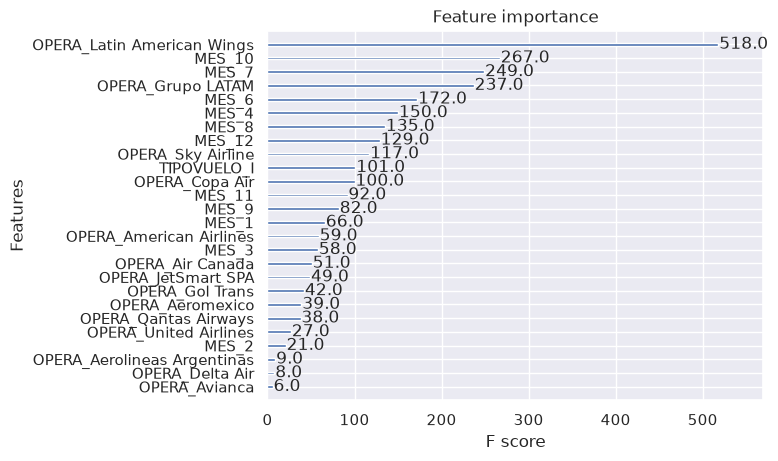

In [42]:
plt.figure(figsize=(10, 5))
plot_importance(xgb_model)

In [43]:
top_10_features = [
    "OPERA_Latin American Wings",
    "MES_7",
    "MES_10",
    "OPERA_Grupo LATAM",
    "MES_12",
    "TIPOVUELO_I",
    "MES_4",
    "MES_11",
    "OPERA_Sky Airline",
    "OPERA_Copa Air",
]

### Data Balance

In [44]:
n_y0 = len(y_train[y_train == 0])
n_y1 = len(y_train[y_train == 1])
scale = n_y0 / n_y1
print(scale)

4.4402380952380955


## 6. Training with Improvement

### 6.a. Data Split

In [45]:
x_train2, x_test2, y_train2, y_test2 = train_test_split(
    features[top_10_features], target, test_size=0.33, random_state=42
)

### 6.b. Model Selection

#### 6.b.i. XGBoost with Feature Importance and with Balance

In [46]:
xgb_model_2 = xgb.XGBClassifier(
    random_state=1, learning_rate=0.01, scale_pos_weight=scale
)
xgb_model_2.fit(x_train2, y_train2)

,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None
,feature_types,None


In [47]:
xgboost_y_preds_2 = xgb_model_2.predict(x_test2)

In [48]:
confusion_matrix(y_test2, xgboost_y_preds_2)

array([[9556, 8738],
       [1313, 2901]])

In [49]:
print(classification_report(y_test2, xgboost_y_preds_2))

              precision    recall  f1-score   support

           0       0.88      0.52      0.66     18294
           1       0.25      0.69      0.37      4214

    accuracy                           0.55     22508
   macro avg       0.56      0.61      0.51     22508
weighted avg       0.76      0.55      0.60     22508



#### 6.b.ii. XGBoost with Feature Importance but without Balance

In [50]:
xgb_model_3 = xgb.XGBClassifier(random_state=1, learning_rate=0.01)
xgb_model_3.fit(x_train2, y_train2)

,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None
,feature_types,None


In [51]:
xgboost_y_preds_3 = xgb_model_3.predict(x_test2)

In [52]:
confusion_matrix(y_test2, xgboost_y_preds_3)

array([[18286,     8],
       [ 4188,    26]])

In [53]:
print(classification_report(y_test2, xgboost_y_preds_3))

              precision    recall  f1-score   support

           0       0.81      1.00      0.90     18294
           1       0.76      0.01      0.01      4214

    accuracy                           0.81     22508
   macro avg       0.79      0.50      0.45     22508
weighted avg       0.80      0.81      0.73     22508



#### 6.b.iii. Logistic Regression with Feature Importante and with Balance

In [54]:
reg_model_2 = LogisticRegression(
    class_weight={1: n_y0 / len(y_train), 0: n_y1 / len(y_train)}
)
reg_model_2.fit(x_train2, y_train2)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*","{0: 0.18381548426626987, 1: 0.8161845157337302}"
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a sol

In [55]:
reg_y_preds_2 = reg_model_2.predict(x_test2)

In [56]:
confusion_matrix(y_test2, reg_y_preds_2)

array([[9487, 8807],
       [1314, 2900]])

In [57]:
print(classification_report(y_test2, reg_y_preds_2))

              precision    recall  f1-score   support

           0       0.88      0.52      0.65     18294
           1       0.25      0.69      0.36      4214

    accuracy                           0.55     22508
   macro avg       0.56      0.60      0.51     22508
weighted avg       0.76      0.55      0.60     22508



#### 6.b.iv. Logistic Regression with Feature Importante but without Balance

In [58]:
reg_model_3 = LogisticRegression()
reg_model_3.fit(x_train2, y_train2)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [59]:
reg_y_preds_3 = reg_model_3.predict(x_test2)

In [60]:
confusion_matrix(y_test2, reg_y_preds_3)

array([[18246,    48],
       [ 4160,    54]])

In [61]:
print(classification_report(y_test2, reg_y_preds_3))

              precision    recall  f1-score   support

           0       0.81      1.00      0.90     18294
           1       0.53      0.01      0.03      4214

    accuracy                           0.81     22508
   macro avg       0.67      0.51      0.46     22508
weighted avg       0.76      0.81      0.73     22508



## 7. Data Science Conclusions

By looking at the results of the 6 trained models, it can be determined:
- There is no noticeable difference in results between XGBoost and LogisticRegression.
- Does not decrease the performance of the model by reducing the features to the 10 most important.
- Improves the model's performance when balancing classes, since it increases the recall of class "1".

**With this, the model to be productive must be the one that is trained with the top 10 features and class balancing, but which one?**

## Conclusion

Selected model: **XGBoost with the top 10 features and class balancing** (`scale_pos_weight` ≈ 4.44).

**How the models were judged.** Missing a delayed flight (a false negative) is the costly mistake, so recall on the delayed class is the primary metric. F1 on the delayed class is the check that recall is not bought with a model that flags nearly every flight. Accuracy is not used to choose, because the unbalanced models reach about 0.81 accuracy while catching almost no delays.

**Results on the delayed class** (test set, n = 4,214):
- XGBoost (top 10, balanced): recall 0.688, precision 0.249, F1 0.366
- LogisticRegression (top 10, balanced): recall 0.688, precision 0.248, F1 0.364

The two models tie on recall and are effectively tied on F1, so the choice between them is a judgment call. XGBoost is selected because it has the marginally higher F1 and its built-in feature importance supports the monitoring analysis. We did not test whether it generalizes better or overfits less, so those claims are not part of the evidence.

**Trade-offs:**
- **Precision is low (about 0.25).** About 52% of test flights (11,639 of 22,508) are flagged as delayed, and about 3 in 4 of those flags are on-time flights. This is the cost of the recall gain.
- **Class balancing is essential.** Unbalanced models reach recall of 0.03 or less and almost never predict a delay.
- **The 0.5 decision threshold was not tuned.** Raising or lowering it moves the balance between recall and precision. Tuning it is the most direct next step to reduce false alarms without giving up much recall.


In [77]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# Each entry: (model name, features, class balancing, fitted model, test features, test target).
# Every metric is computed from the fitted models above, not typed in by hand.
models = [
    ("XGBoost", "All (37)", "No", xgb_model, x_test, y_test),
    ("LogisticRegression", "All (37)", "No", reg_model, x_test, y_test),
    ("XGBoost", "Top 10", "No", xgb_model_3, x_test2, y_test2),
    ("LogisticRegression", "Top 10", "No", reg_model_3, x_test2, y_test2),
    ("XGBoost", "Top 10", "Yes", xgb_model_2, x_test2, y_test2),
    ("LogisticRegression", "Top 10", "Yes", reg_model_2, x_test2, y_test2),
]

rows = []
for number, (name, features, balanced, model, x, y) in enumerate(models, start=1):
    y_pred = model.predict(x)
    rows.append(
        {
            "#": number,
            "Model": name,
            "Features": features,
            "Class balancing": balanced,
            "Precision (1)": precision_score(y, y_pred),
            "Recall (1)": recall_score(y, y_pred),
            "F1 (1)": f1_score(y, y_pred),
            "Accuracy": accuracy_score(y, y_pred),
        }
    )

model_comparison = pd.DataFrame(rows).set_index("#")
metric_columns = ["Precision (1)", "Recall (1)", "F1 (1)", "Accuracy"]
(
    model_comparison.style.format("{:.3f}", subset=metric_columns).highlight_max(
        subset=metric_columns, axis=0, props="font-weight: bold;"
    )
)

,Model,Features,Class balancing,Precision (1),Recall (1),F1 (1),Accuracy
#,,,,,,,
1,XGBoost,All (37),No,0.000,0.000,0.000,0.813
2,LogisticRegression,All (37),No,0.559,0.030,0.058,0.814
3,XGBoost,Top 10,No,0.765,0.006,0.012,0.814
4,LogisticRegression,Top 10,No,0.529,0.013,0.025,0.813
5,XGBoost,Top 10,Yes,0.249,0.688,0.366,0.553
6,LogisticRegression,Top 10,Yes,0.248,0.688,0.364,0.550


**Reading the table**
- Without balancing, every model misses almost all delays (recall ≤ 0.03), even though accuracy is about 0.81. Accuracy is misleading here because most flights are on time.
- Balancing raises recall on delays from ≤ 0.03 to about 0.69, at the cost of precision (about 0.25) and accuracy (about 0.55).
- Models 5 and 6 are effectively tied. Model 5 is the selected model, as explained in the conclusion.